## Chủ đề số 14: Bank marketing
## Bài toán: Dự đoán khách hàng có đăng ký gửi tiền kỳ hạn hay không (Yes/No) 
## Loại bài toán: Classification

### Tập dữ liệu: UCI Bank Marketing (https://archive.ics.uci.edu/dataset/222/bank+marketing)
### Sử dụng 4 thuật toán: Logistic Regression, KNN, Decision Tree, RandomForest
### Độ đo: F1, Recall, ROC-AUC

### 1. Đọc dữ liệu

In [15]:
import pandas as pd

df = pd.read_csv("data/bank-additional.csv", sep=";")
df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,30,blue-collar,married,basic.9y,no,yes,no,cellular,may,fri,...,2,999,0,nonexistent,-1.8,92.893,-46.2,1.313,5099.1,no
1,39,services,single,high.school,no,no,no,telephone,may,fri,...,4,999,0,nonexistent,1.1,93.994,-36.4,4.855,5191.0,no
2,25,services,married,high.school,no,yes,no,telephone,jun,wed,...,1,999,0,nonexistent,1.4,94.465,-41.8,4.962,5228.1,no
3,38,services,married,basic.9y,no,unknown,unknown,telephone,jun,fri,...,3,999,0,nonexistent,1.4,94.465,-41.8,4.959,5228.1,no
4,47,admin.,married,university.degree,no,yes,no,cellular,nov,mon,...,1,999,0,nonexistent,-0.1,93.200,-42.0,4.191,5195.8,no


### 2. Khám phá dữ liệu EDA

In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Đọc dữ liệu
df = pd.read_csv(
    "data/bank-additional-full.csv",
    sep=";"
)

# Hiển thị 5 dòng đầu tiên
display(df.head())

# Kích thước dữ liệu
print("Số dòng:", df.shape[0])
print("Số cột:", df.shape[1])

# Thông tin dữ liệu
df.info()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


Số dòng: 41188
Số cột: 21
<class 'pandas.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  str    
 2   marital         41188 non-null  str    
 3   education       41188 non-null  str    
 4   default         41188 non-null  str    
 5   housing         41188 non-null  str    
 6   loan            41188 non-null  str    
 7   contact         41188 non-null  str    
 8   month           41188 non-null  str    
 9   day_of_week     41188 non-null  str    
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  str    
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   

y
no     36548
yes     4640
Name: count, dtype: int64
y
no     88.734583
yes    11.265417
Name: proportion, dtype: float64


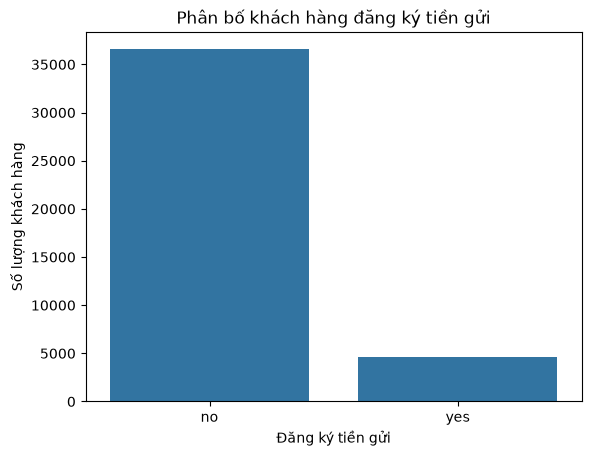

In [17]:
print(df["y"].value_counts())
print(df["y"].value_counts(normalize=True) * 100)

sns.countplot(data=df, x="y")
plt.title("Phân bố khách hàng đăng ký tiền gửi")
plt.xlabel("Đăng ký tiền gửi")
plt.ylabel("Số lượng khách hàng")
plt.show()

### 3. Tiền xử lý dữ liệu

In [18]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Giữ "unknown" như một nhóm riêng; loại bản ghi trùng và thiếu nhãn.
df_model = df.drop_duplicates().dropna(subset=["y"]).copy()

# duration chỉ biết sau cuộc gọi, không dùng để dự đoán trước cuộc gọi.
X = df_model.drop(columns=["y", "duration"])
y = df_model["y"].map({"no": 0, "yes": 1})

numeric_features = X.select_dtypes(include="number").columns.tolist()
categorical_features = X.select_dtypes(exclude="number").columns.tolist()

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y,
)

numeric_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]
)
categorical_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_pipeline, numeric_features),
        ("cat", categorical_pipeline, categorical_features),
    ]
)

# Chỉ fit trên train để tránh rò rỉ thông tin từ tập test.
X_train = preprocessor.fit_transform(X_train_raw)
X_test = preprocessor.transform(X_test_raw)
feature_names = preprocessor.get_feature_names_out()

print(f"Số dòng sau khi loại trùng/thiếu nhãn: {len(df_model)}")
print(f"Số đặc trưng sau mã hóa: {len(feature_names)}")
print(f"Train: X={X_train.shape}, y={y_train.shape}")
print(f"Test:  X={X_test.shape}, y={y_test.shape}")
print("Tỷ lệ nhãn trong train (%):")
print(y_train.map({0: "no", 1: "yes"}).value_counts(normalize=True).mul(100).round(2))

Số dòng sau khi loại trùng/thiếu nhãn: 41176
Số đặc trưng sau mã hóa: 62
Train: X=(32940, 62), y=(32940,)
Test:  X=(8236, 62), y=(8236,)
Tỷ lệ nhãn trong train (%):
y
no     88.73
yes    11.27
Name: proportion, dtype: float64


### 4. Thuật toán Logistic Regression

In [19]:

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

# Bước 1: Khởi tạo mô hình
lr_model = LogisticRegression(
    max_iter=2000,
    class_weight="balanced",
    random_state=42
)

# Bước 2: Huấn luyện mô hình
lr_model.fit(X_train, y_train)

# Bước 3: Dự đoán trên tập kiểm tra
y_pred_lr = lr_model.predict(X_test)

# Lấy xác suất của lớp đăng ký "yes"
# Cách này áp dụng khi nhãn y là 0/1 hoặc False/True
classes = list(lr_model.classes_)
yes_index = classes.index(1) if 1 in classes else classes.index("yes")
y_prob_lr = lr_model.predict_proba(X_test)[:, yes_index]

# Bước 4: Đánh giá mô hình
print("===== LOGISTIC REGRESSION =====")
print(f"Accuracy:  {accuracy_score(y_test, y_pred_lr):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_lr, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_lr, zero_division=0):.4f}")
print(f"F1-score:  {f1_score(y_test, y_pred_lr, zero_division=0):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, y_prob_lr):.4f}")

# Báo cáo chi tiết
print("\n===== CLASSIFICATION REPORT =====")
print(classification_report(y_test, y_pred_lr, zero_division=0))

# Bước 5: Ma trận nhầm lẫn (không cần Matplotlib)
print("===== CONFUSION MATRIX =====")
print(confusion_matrix(y_test, y_pred_lr))

# Bước 6: Lưu kết quả để so sánh các mô hình
lr_result = {
    "Model": "Logistic Regression",
    "Accuracy": accuracy_score(y_test, y_pred_lr),
    "Precision": precision_score(y_test, y_pred_lr, zero_division=0),
    "Recall": recall_score(y_test, y_pred_lr, zero_division=0),
    "F1-score": f1_score(y_test, y_pred_lr, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, y_prob_lr)
}

print("\nĐã lưu kết quả vào biến lr_result.")


===== LOGISTIC REGRESSION =====
Accuracy:  0.8303
Precision: 0.3591
Recall:    0.6455
F1-score:  0.4615
ROC-AUC:   0.8002

===== CLASSIFICATION REPORT =====
              precision    recall  f1-score   support

           0       0.95      0.85      0.90      7308
           1       0.36      0.65      0.46       928

    accuracy                           0.83      8236
   macro avg       0.65      0.75      0.68      8236
weighted avg       0.88      0.83      0.85      8236

===== CONFUSION MATRIX =====
[[6239 1069]
 [ 329  599]]

Đã lưu kết quả vào biến lr_result.


### 5. KNN
#### 5.1.Giới thiệu 
K-Nearest Neighbors (KNN) là thuật toán học máy có giám sát, được sử dụng trong các bài toán phân loại và hồi quy.

Đối với bài toán Bank Marketing, KNN dự đoán khách hàng có đăng ký tiền gửi kỳ hạn hay không dựa trên nhãn của K khách hàng gần nhất trong không gian đặc trưng.

Trong thực nghiệm baseline, mô hình sử dụng K = 5 và khoảng cách Euclidean.

In [20]:
from sklearn.neighbors import KNeighborsClassifier

# Khởi tạo mô hình KNN baseline
knn = KNeighborsClassifier(
    n_neighbors=5,
    metric="euclidean"
)

# Huấn luyện mô hình
knn.fit(X_train, y_train)

print("Đã huấn luyện KNN baseline thành công!")

Đã huấn luyện KNN baseline thành công!


#### 5.2. Dự đoán kết quả

Sau khi huấn luyện, mô hình KNN được sử dụng để dự đoán khả năng đăng ký tiền gửi kỳ hạn của khách hàng trên tập kiểm tra.

Nhãn 0 biểu thị khách hàng không đăng ký, trong khi nhãn 1 biểu thị khách hàng có đăng ký.

In [21]:
# Dự đoán nhãn
y_pred_knn = knn.predict(X_test)

# Xác suất dự đoán lớp 1
y_prob_knn = knn.predict_proba(X_test)[:, 1]

print("10 kết quả dự đoán đầu tiên:")
print(y_pred_knn[:10])

10 kết quả dự đoán đầu tiên:
[0 1 0 0 0 0 0 0 0 0]


#### 5.3. Đánh giá mô hình KNN

Đánh giá hiệu suất mô hình KNN thông qua các chỉ số Accuracy, Precision, Recall, F1-score và ROC-AUC.

In [22]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

accuracy = accuracy_score(y_test, y_pred_knn)
precision = precision_score(y_test, y_pred_knn, zero_division=0)
recall = recall_score(y_test, y_pred_knn, zero_division=0)
f1 = f1_score(y_test, y_pred_knn, zero_division=0)
auc = roc_auc_score(y_test, y_prob_knn)

print("KẾT QUẢ KNN BASELINE")
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-score : {f1:.4f}")
print(f"ROC-AUC  : {auc:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_knn,
    target_names=["No", "Yes"],
    zero_division=0
))

KẾT QUẢ KNN BASELINE
Accuracy : 0.8955
Precision: 0.5663
Recall   : 0.3082
F1-score : 0.3992
ROC-AUC  : 0.7404

Classification Report:
              precision    recall  f1-score   support

          No       0.92      0.97      0.94      7308
         Yes       0.57      0.31      0.40       928

    accuracy                           0.90      8236
   macro avg       0.74      0.64      0.67      8236
weighted avg       0.88      0.90      0.88      8236



#### Confusion Matrix

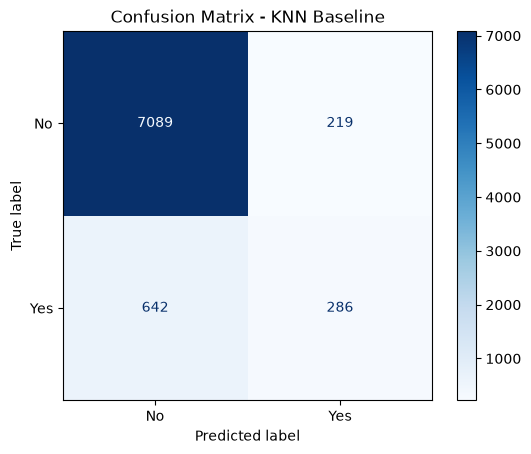

In [23]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_knn,
    display_labels=["No", "Yes"],
    cmap="Blues"
)

plt.title("Confusion Matrix - KNN Baseline")
plt.show()

#### ROC Curve

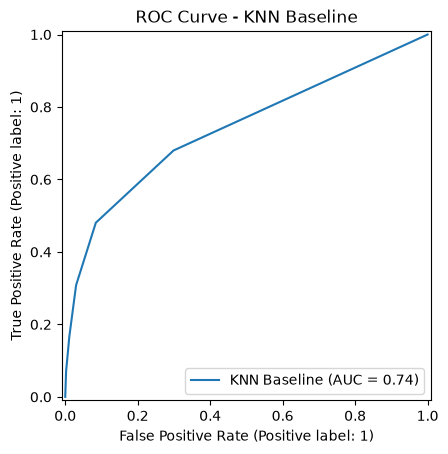

In [24]:
from sklearn.metrics import RocCurveDisplay

RocCurveDisplay.from_predictions(
    y_test,
    y_prob_knn,
    name="KNN Baseline"
)

plt.title("ROC Curve - KNN Baseline")
plt.show()

### 6. Thuật toán Decision Tree

#### Khởi tạo và huấn luyện mô hình

In [ ]:
from sklearn.tree import DecisionTreeClassifier

#Khởi tạo mô hình Decision Tree
dt_model = DecisionTreeClassifier(
    max_depth=8,
    min_samples_split=20,
    min_samples_leaf=10,
    class_weight="balanced",
    random_state=42
)

dt_model.fit(X_train, y_train)

print("Đã huấn luyện Decision Tree thành công!")

Đã huấn luyện Decision Tree thành công!


#### Dự đoán kết quả

In [ ]:
y_pred_dt = dt_model.predict(X_test)

yes_index = list(dt_model.classes_).index(1)
y_prob_dt = dt_model.predict_proba(X_test)[:, yes_index]

print("10 kết quả dự đoán đầu tiên:")
print(y_pred_dt[:10])

print("\n10 xác suất dự đoán đăng ký đầu tiên:")
print(y_prob_dt[:10])

10 kết quả dự đoán đầu tiên:
[0 1 1 1 0 0 1 0 0 0]

10 xác suất dự đoán đăng ký đầu tiên:
[0.31636964 0.97172695 0.52496574 0.52496574 0.34207327 0.23060241
 0.52496574 0.24334486 0.34207327 0.34207327]


#### Đánh giá mô hình

In [35]:
# Tính các độ đo đánh giá
accuracy_dt = accuracy_score(y_test, y_pred_dt)
precision_dt = precision_score(y_test, y_pred_dt, zero_division=0)
recall_dt = recall_score(y_test, y_pred_dt, zero_division=0)
f1_dt = f1_score(y_test, y_pred_dt, zero_division=0)
auc_dt = roc_auc_score(y_test, y_prob_dt)

# Hiển thị kết quả
print("===== DECISION TREE BASELINE =====")
print(f"Accuracy : {accuracy_dt:.4f}")
print(f"Precision: {precision_dt:.4f}")
print(f"Recall   : {recall_dt:.4f}")
print(f"F1-score : {f1_dt:.4f}")
print(f"ROC-AUC  : {auc_dt:.4f}")

print("\n===== CLASSIFICATION REPORT =====")
print(classification_report(
    y_test,
    y_pred_dt,
    labels=[0, 1],
    target_names=["No", "Yes"],
    zero_division=0
))

# Lưu kết quả
dt_result = {
    "Model": "Decision Tree",
    "Accuracy": accuracy_dt,
    "Precision": precision_dt,
    "Recall": recall_dt,
    "F1-score": f1_dt,
    "ROC-AUC": auc_dt
}

print("\nĐã lưu kết quả vào biến dt_result.")

===== DECISION TREE BASELINE =====
Accuracy : 0.8263
Precision: 0.3530
Recall   : 0.6509
F1-score : 0.4577
ROC-AUC  : 0.7932

===== CLASSIFICATION REPORT =====
              precision    recall  f1-score   support

          No       0.95      0.85      0.90      7308
         Yes       0.35      0.65      0.46       928

    accuracy                           0.83      8236
   macro avg       0.65      0.75      0.68      8236
weighted avg       0.88      0.83      0.85      8236


Đã lưu kết quả vào biến dt_result.


#### Ma trận nhầm lẫn

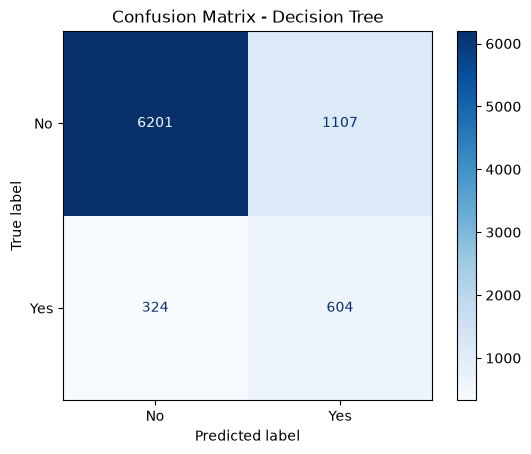

In [32]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_dt,
    display_labels=["No", "Yes"],
    cmap="Blues"
)

plt.title("Confusion Matrix - Decision Tree")
plt.show()

#### ROC Curve

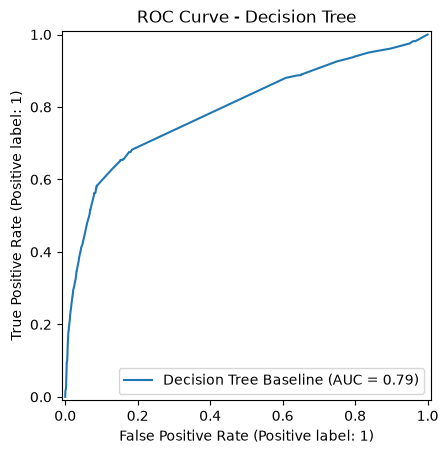

In [36]:
RocCurveDisplay.from_predictions(
    y_test,
    y_prob_dt,
    name="Decision Tree Baseline"
)

plt.title("ROC Curve - Decision Tree")
plt.show()

#### Đánh giá độ quan trọng của thuộc tính

Top 10 đặc trưng quan trọng nhất của Decision Tree:
num__nr.employed         0.6288
num__cons.conf.idx       0.1344
num__euribor3m           0.0422
num__cons.price.idx      0.0356
num__pdays               0.0306
num__age                 0.0207
cat__month_oct           0.0195
num__campaign            0.0191
cat__poutcome_failure    0.0123
cat__default_unknown     0.0101
dtype: float64


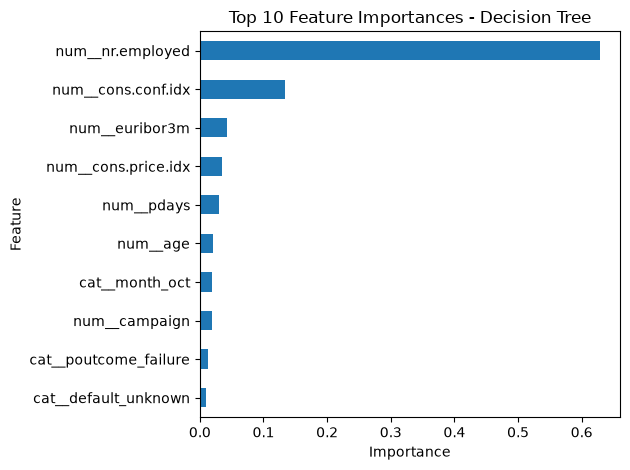

In [37]:
# Tính độ quan trọng của từng đặc trưng
importance_dt = pd.Series(
    dt_model.feature_importances_,
    index=feature_names
)

# Hiển thị 10 đặc trưng quan trọng nhất
top10_dt = importance_dt.sort_values(ascending=False).head(10)

print("Top 10 đặc trưng quan trọng nhất của Decision Tree:")
print(top10_dt.round(4))

# Trực quan hóa
top10_dt.sort_values().plot(kind="barh")

plt.title("Top 10 Feature Importances - Decision Tree")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

### 7. Thuật toán RandomForest

F1-score: 0.4585
Recall:   0.4698
ROC-AUC:  0.7868
Top 10 feature importances:
num__age               0.1417
num__euribor3m         0.1210
num__campaign          0.0790
num__nr.employed       0.0594
num__emp.var.rate      0.0447
num__cons.conf.idx     0.0297
num__pdays             0.0231
num__cons.price.idx    0.0226
cat__housing_yes       0.0191
cat__housing_no        0.0187
dtype: float64


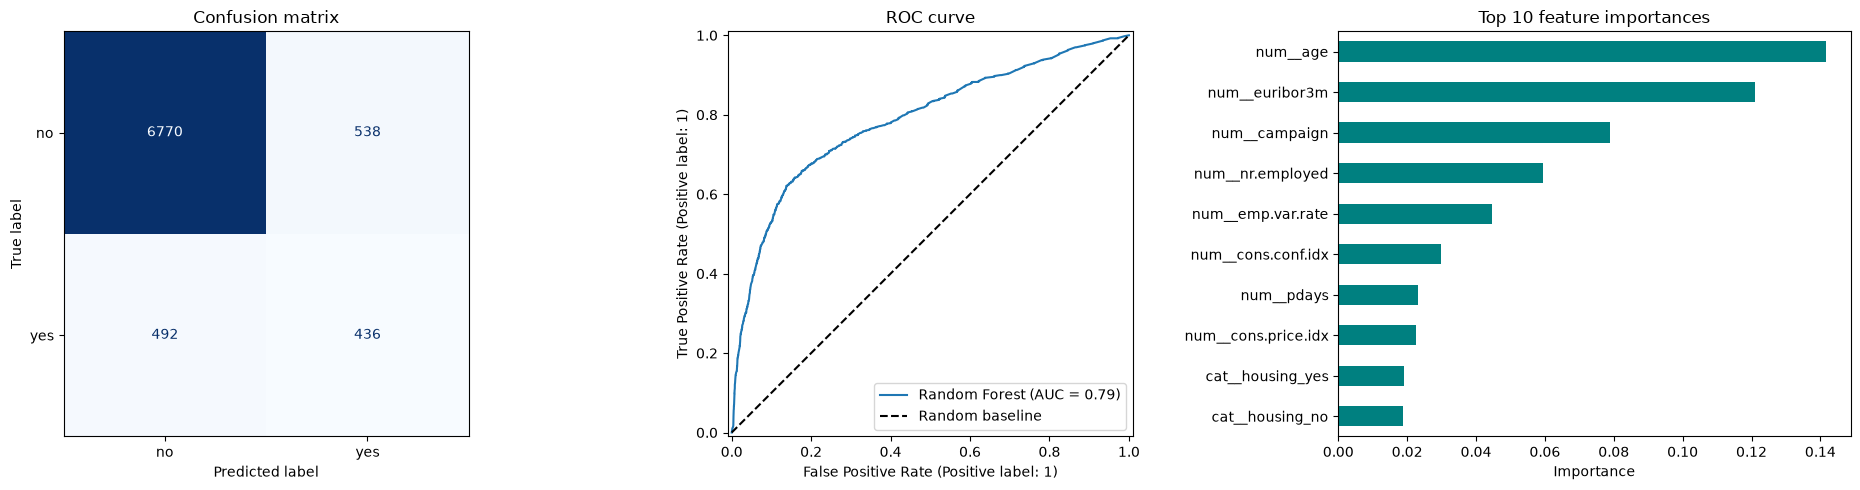

In [26]:
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    f1_score,
    recall_score,
    RocCurveDisplay,
    roc_auc_score,
)

random_forest = RandomForestClassifier(
    n_estimators=300,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1,
)
random_forest.fit(X_train, y_train)

y_pred = random_forest.predict(X_test)
y_proba = random_forest.predict_proba(X_test)[:, 1]

print(f"F1-score: {f1_score(y_test, y_pred, zero_division=0):.4f}")
print(f"Recall:   {recall_score(y_test, y_pred, zero_division=0):.4f}")
print(f"ROC-AUC:  {roc_auc_score(y_test, y_proba):.4f}")

importance = pd.Series(random_forest.feature_importances_, index=feature_names)
print("Top 10 feature importances:")
print(importance.sort_values(ascending=False).head(10).round(4))

# Trực quan hóa kết quả trên tập test.
fig, axes = plt.subplots(1, 3, figsize=(19, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=[0, 1],
    display_labels=["no", "yes"],
    cmap="Blues",
    ax=axes[0],
    colorbar=False,
)
axes[0].set_title("Confusion matrix")

RocCurveDisplay.from_predictions(y_test, y_proba, ax=axes[1], name="Random Forest")
axes[1].plot([0, 1], [0, 1], "k--", label="Random baseline")
axes[1].set_title("ROC curve")
axes[1].legend(loc="lower right")

top_importance = importance.sort_values().tail(10)
top_importance.plot(kind="barh", ax=axes[2], color="teal")
axes[2].set_title("Top 10 feature importances")
axes[2].set_xlabel("Importance")
axes[2].set_ylabel("")

plt.tight_layout()
plt.show()

### 8. So sánh kết quả các mô hình 
